<a href="https://colab.research.google.com/github/DhaiHamoud/Fraud-Detection-in-the-Financial-Transaction-Market/blob/main/notebooks/02_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [36]:
import gdown, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
gdown.download(id='1VV0JLvtGmc88sN0zx8AxctvA4C-VClCs', output='clean.parquet', quiet=False)
df = pd.read_parquet('clean.parquet')

Downloading...
From (original): https://drive.google.com/uc?id=1VV0JLvtGmc88sN0zx8AxctvA4C-VClCs
From (redirected): https://drive.google.com/uc?id=1VV0JLvtGmc88sN0zx8AxctvA4C-VClCs&confirm=t&uuid=1692045b-a62f-4c7f-b9d9-089a14d2885d
To: /content/clean.parquet
100%|██████████| 139M/139M [00:01<00:00, 78.6MB/s]


## 1. Target Distribution — **Turki**

In [37]:
df["is_fraud"].value_counts()

,count
is_fraud,
0,1842743
1,9651


Number of legitimate transactions are 1,842,743 , and the fraud ones are 9651.

In [38]:
df["is_fraud"].value_counts(normalize=True) * 100

,proportion
is_fraud,
0,99.478999
1,0.521001


99.48% of the transactions are legitimate, and the fraud transcations are 0.52%

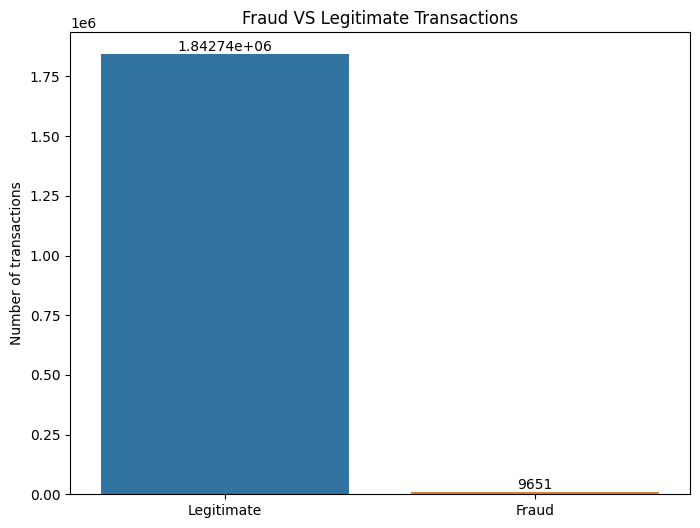

In [40]:
plt.figure(figsize=(8,6))
fig = sns.countplot(df, x="is_fraud",hue="is_fraud", legend=False);
plt.title("Fraud VS Legitimate Transactions")
fig.set_xticks([0, 1])
fig.set_xticklabels(["Legitimate", "Fraud"])
plt.ylabel("Number of transactions")
for c in fig.containers:
    fig.bar_label(c)
plt.xlabel("");

**Observation:** The dataset is highly imbalanced. Legitimate transactions are far more common than fraud, so the fraud bar is barely visible.

**Fraud is 0.52% of all transactions** (9,651 out of 1,852,394), while legitimate transactions are 99.48%. The fraud bar is barely visible because the data is highly imbalanced.

**Effect on accuracy:** Accuracy is not a reliable metric here. A model that always predicts "legitimate" would score about 99.5% accuracy while catching no fraud at all.